In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, adjusted_rand_score
import joblib



In [4]:

# Step 1: Load and Explore the Iris Dataset
# ---------------------------------------------------------
df = pd.read_csv('Iris.csv')



In [5]:
# Features for clustering (excluding 'Id' and categorical 'Species')
feature_cols = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
X = df[feature_cols]
y_true = df['Species']



In [12]:
# ---------------------------------------------------------
# Step 2: Feature Scaling
# ---------------------------------------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


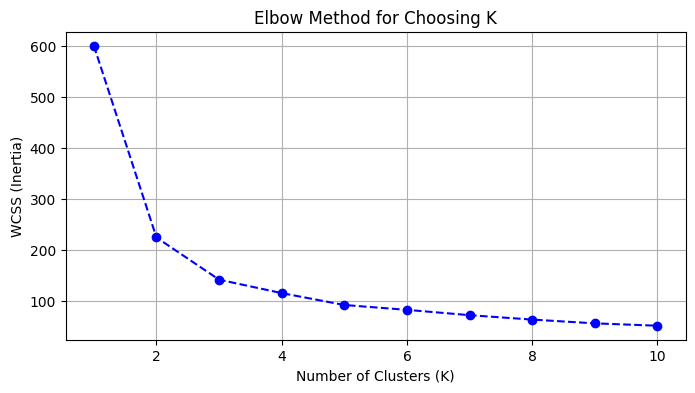

In [8]:

# ---------------------------------------------------------
# Step 3: Elbow Method to Find Optimal K
# ---------------------------------------------------------
wcss = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_values, wcss, marker='o', linestyle='--', color='b')
plt.title('Elbow Method for Choosing K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.grid(True)
plt.show()



Explained Variance Ratio by top 2 components: 95.80%


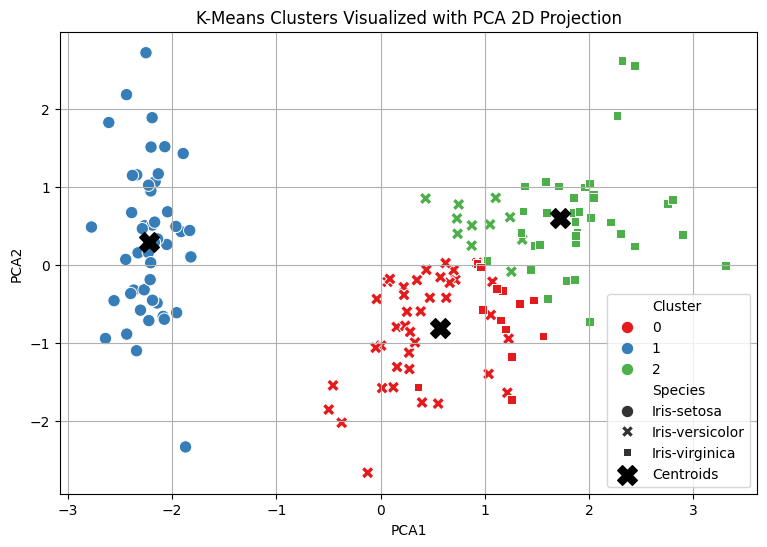

In [11]:
# ---------------------------------------------------------
# Step 4: K-Means Clustering (k=3)
# ---------------------------------------------------------
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans_3.fit_predict(X_scaled)

# ---------------------------------------------------------
# Step 5: Dimensionality Reduction using PCA
# ---------------------------------------------------------
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df['PCA1'] = X_pca[:, 0]
df['PCA2'] = X_pca[:, 1]

print(f"Explained Variance Ratio by top 2 components: {pca.explained_variance_ratio_.sum():.2%}")

# Visualizing Clusters on 2D PCA Space
plt.figure(figsize=(9, 6))
sns.scatterplot(x='PCA1', y='PCA2', hue='Cluster', style='Species', data=df, palette='Set1', s=80)

# Plotting Centroids transformed to PCA Space
centroids_pca = pca.transform(kmeans_3.cluster_centers_)
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], c='black', marker='X', s=200, label='Centroids')

plt.title('K-Means Clusters Visualized with PCA 2D Projection')
plt.legend()
plt.grid(True)
plt.show()



In [10]:
# ---------------------------------------------------------
# Step 6: Compare Predicted Clusters vs True Labels
# ---------------------------------------------------------
# Contingency Table / Confusion Matrix mapping
crosstab = pd.crosstab(df['Species'], df['Cluster'], rownames=['Actual Species'], colnames=['Predicted Cluster'])
print("\n--- Crosstab: Actual Species vs Predicted Cluster ---")
print(crosstab)

ari_score = adjusted_rand_score(y_true, df['Cluster'])
print(f"\nAdjusted Rand Index (ARI): {ari_score:.4f}")




--- Crosstab: Actual Species vs Predicted Cluster ---
Predicted Cluster   0   1   2
Actual Species               
Iris-setosa         0  50   0
Iris-versicolor    39   0  11
Iris-virginica     14   0  36

Adjusted Rand Index (ARI): 0.6201


In [9]:
# ---------------------------------------------------------
# Step 7: Save & Load Model (joblib)
# ---------------------------------------------------------
# Save both scaler and kmeans model
joblib.dump(kmeans_3, 'kmeans_iris_model.pkl')
joblib.dump(scaler, 'scaler_iris.pkl')
joblib.dump(pca, 'pca_iris.pkl')

print("\nModel, Scaler, and PCA successfully saved using joblib!")

# Example loading
loaded_model = joblib.load('kmeans_iris_model.pkl')
loaded_scaler = joblib.load('scaler_iris.pkl')


Model, Scaler, and PCA successfully saved using joblib!
